In [1]:
import matplotlib.pyplot as plt
import numpy as np
import torch
from dtaianomaly.visualization import plot_demarcated_anomalies
from dtaianomaly.windowing import compute_window_size, sliding_window

from hydraad import Hydra, SparseScaler, TSBADLoader

In [2]:
def perform_analysis(path: str) -> None:
    # Load data
    dataset = TSBADLoader(path).load()
    X_test = dataset.X_test
    y_test = dataset.y_test

    # Sliding window
    window_size = compute_window_size(X_test, "fft")
    stride = window_size // 4
    windows = sliding_window(X_test, window_size, stride)
    windows = torch.Tensor(np.expand_dims(windows, 1))

    # Create embedding
    k = 8
    g = 512 // k
    transformer = Hydra(
        n_kernels=k,
        n_groups=g,
    )
    embedding = transformer.fit_transform(windows)
    embedding_ = SparseScaler().fit_transform(embedding)

    # Plot embedding
    fig, axs = plt.subplots(4, 1, figsize=(20, 15), height_ratios=[1, 3, 2, 2])
    plot_demarcated_anomalies(X_test, y_test, figsize=(20, 3), ax=axs[0])
    axs[0].set_xlim(0, X_test.shape[0])
    axs[1].imshow(embedding_.T, aspect="auto", cmap="gist_gray_r")
    axs[2].plot(embedding_)
    axs[2].set_xlim(0, embedding_.shape[0])

    qs = [0.5, 0.6, 0.7, 0.8, 0.9, 1.0]
    for q in qs:
        axs[3].plot(torch.quantile(embedding_.abs(), q, dim=1), label=f"q={q}")
    axs[3].set_xlim(0, embedding_.shape[0])
    plt.legend(
        loc="lower center", bbox_to_anchor=(0.5, 0.9), ncol=len(qs), frameon=False
    )

    fig.tight_layout()

In [3]:
from scripts.run_experiment import initialize_dataloaders

loaders = initialize_dataloaders("../data", dimension="U", subset="Tuning")
for loader in loaders:
    dataset = loader.load()
    X_test = dataset.X_test
    y_test = dataset.y_test
    if "UCR" in loader.path:
        print(X_test.shape[0], loader.path)

12000 ../data/TSB-AD-U/305_UCR_id_3_Medical_tr_3000_1st_5948.csv
79795 ../data/TSB-AD-U/312_UCR_id_10_Facility_tr_19948_1st_52000.csv
195250 ../data/TSB-AD-U/323_UCR_id_21_HumanActivity_tr_48812_1st_128430.csv
11406 ../data/TSB-AD-U/347_UCR_id_45_Sensor_tr_2851_1st_5365.csv
8184 ../data/TSB-AD-U/386_UCR_id_84_Environment_tr_2046_1st_5703.csv
59302 ../data/TSB-AD-U/429_UCR_id_127_Medical_tr_14825_1st_29000.csv


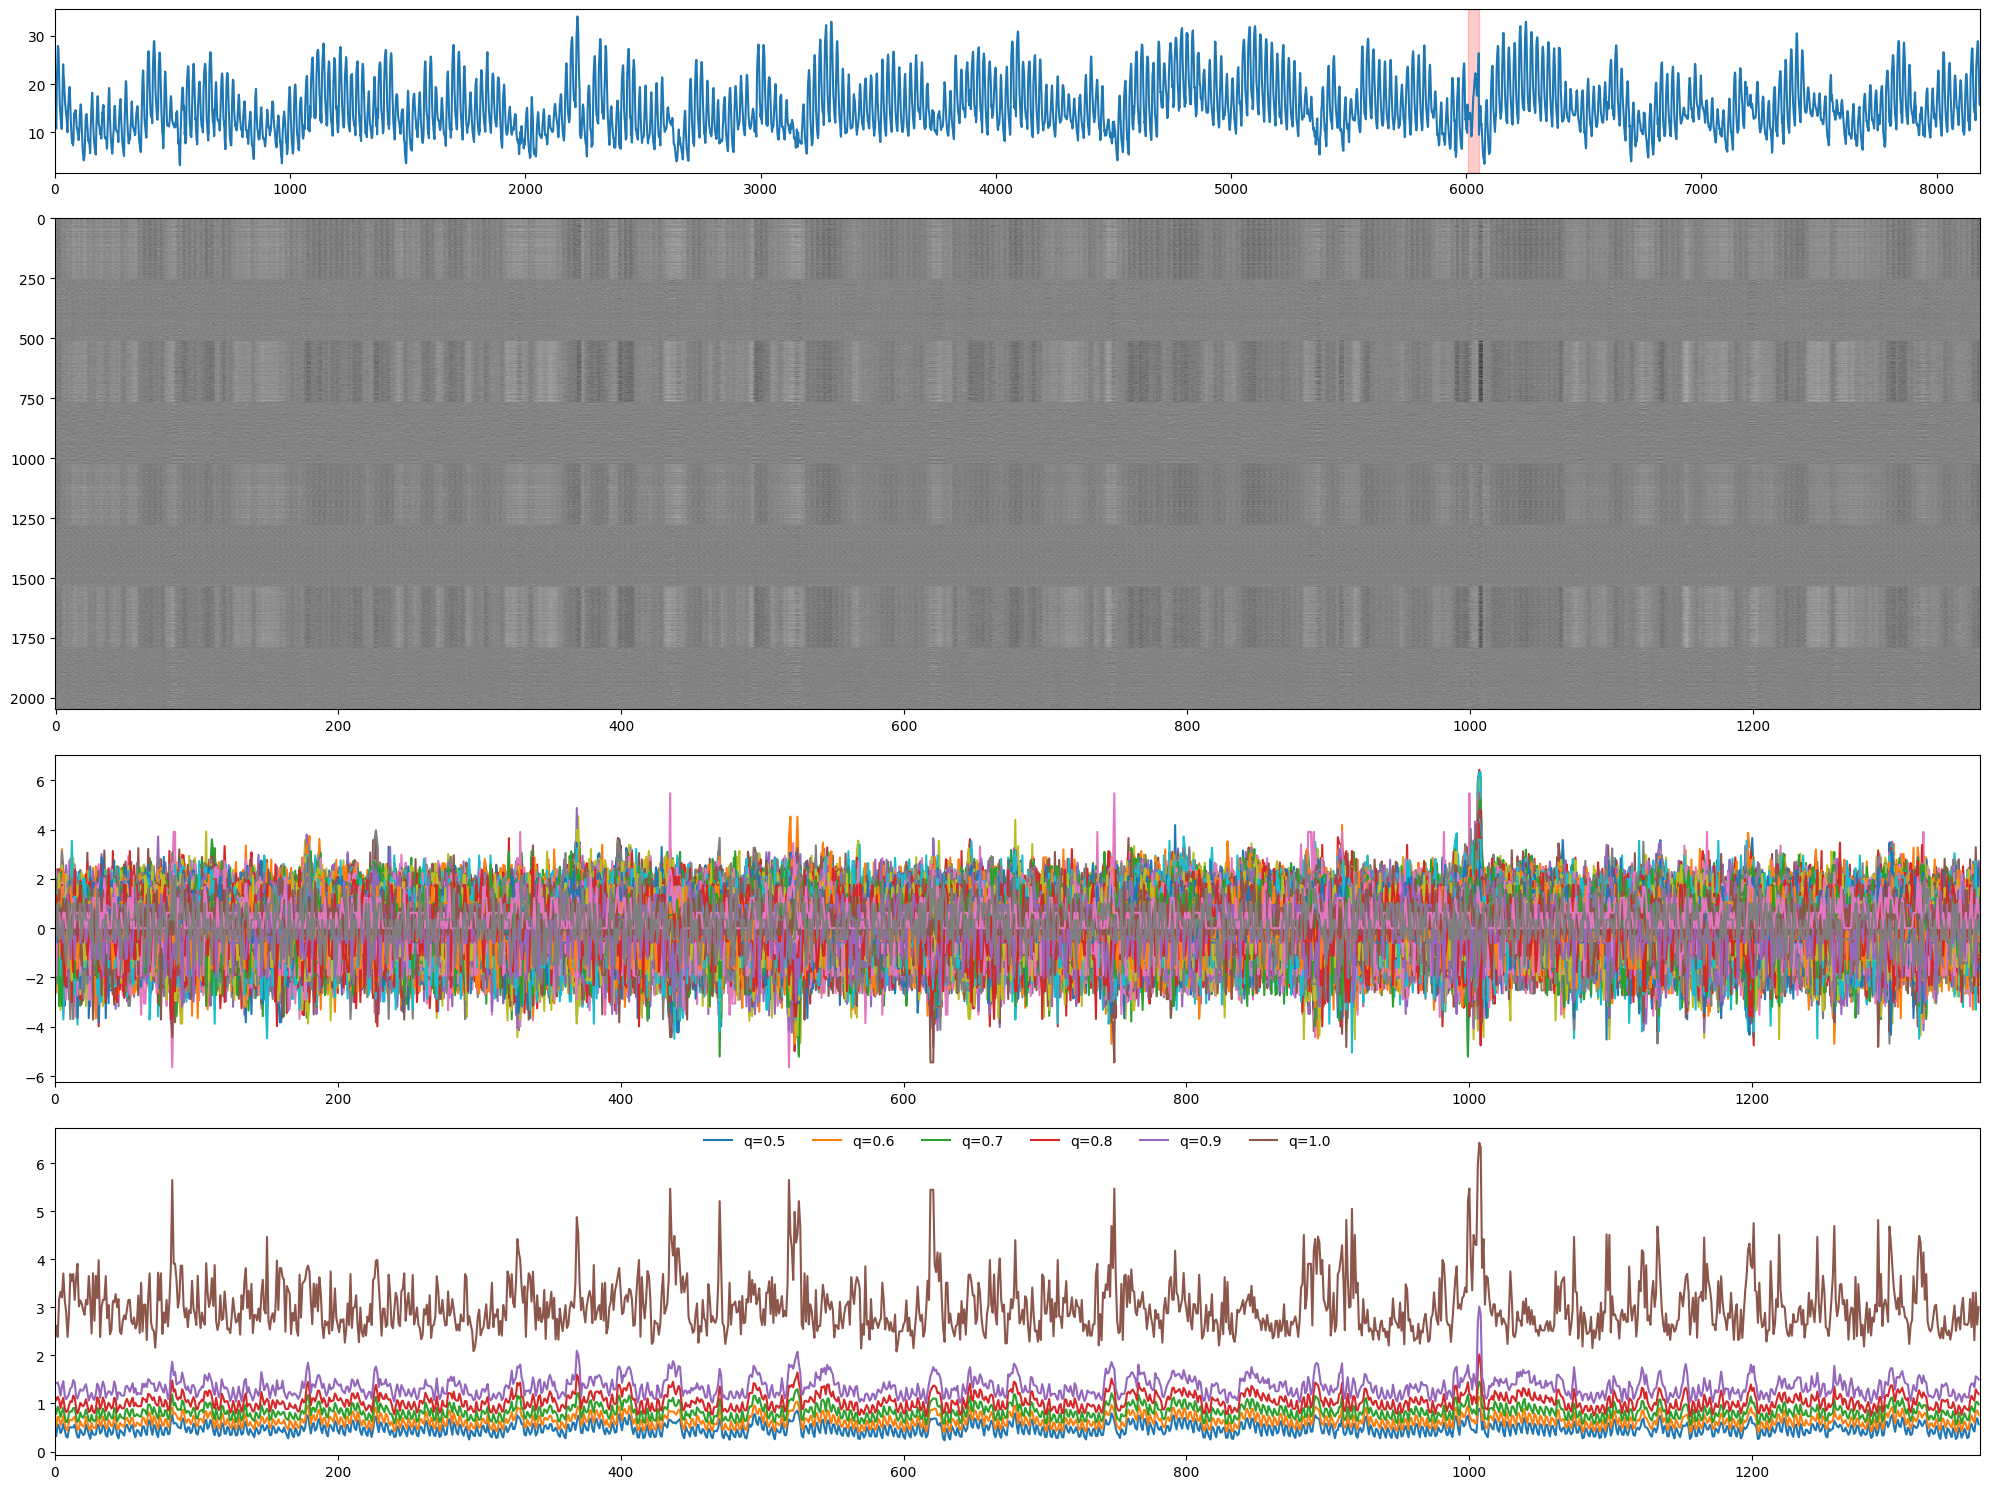

In [4]:
perform_analysis("../data/TSB-AD-U/463_UCR_id_161_Environment_tr_2046_1st_6006.csv")

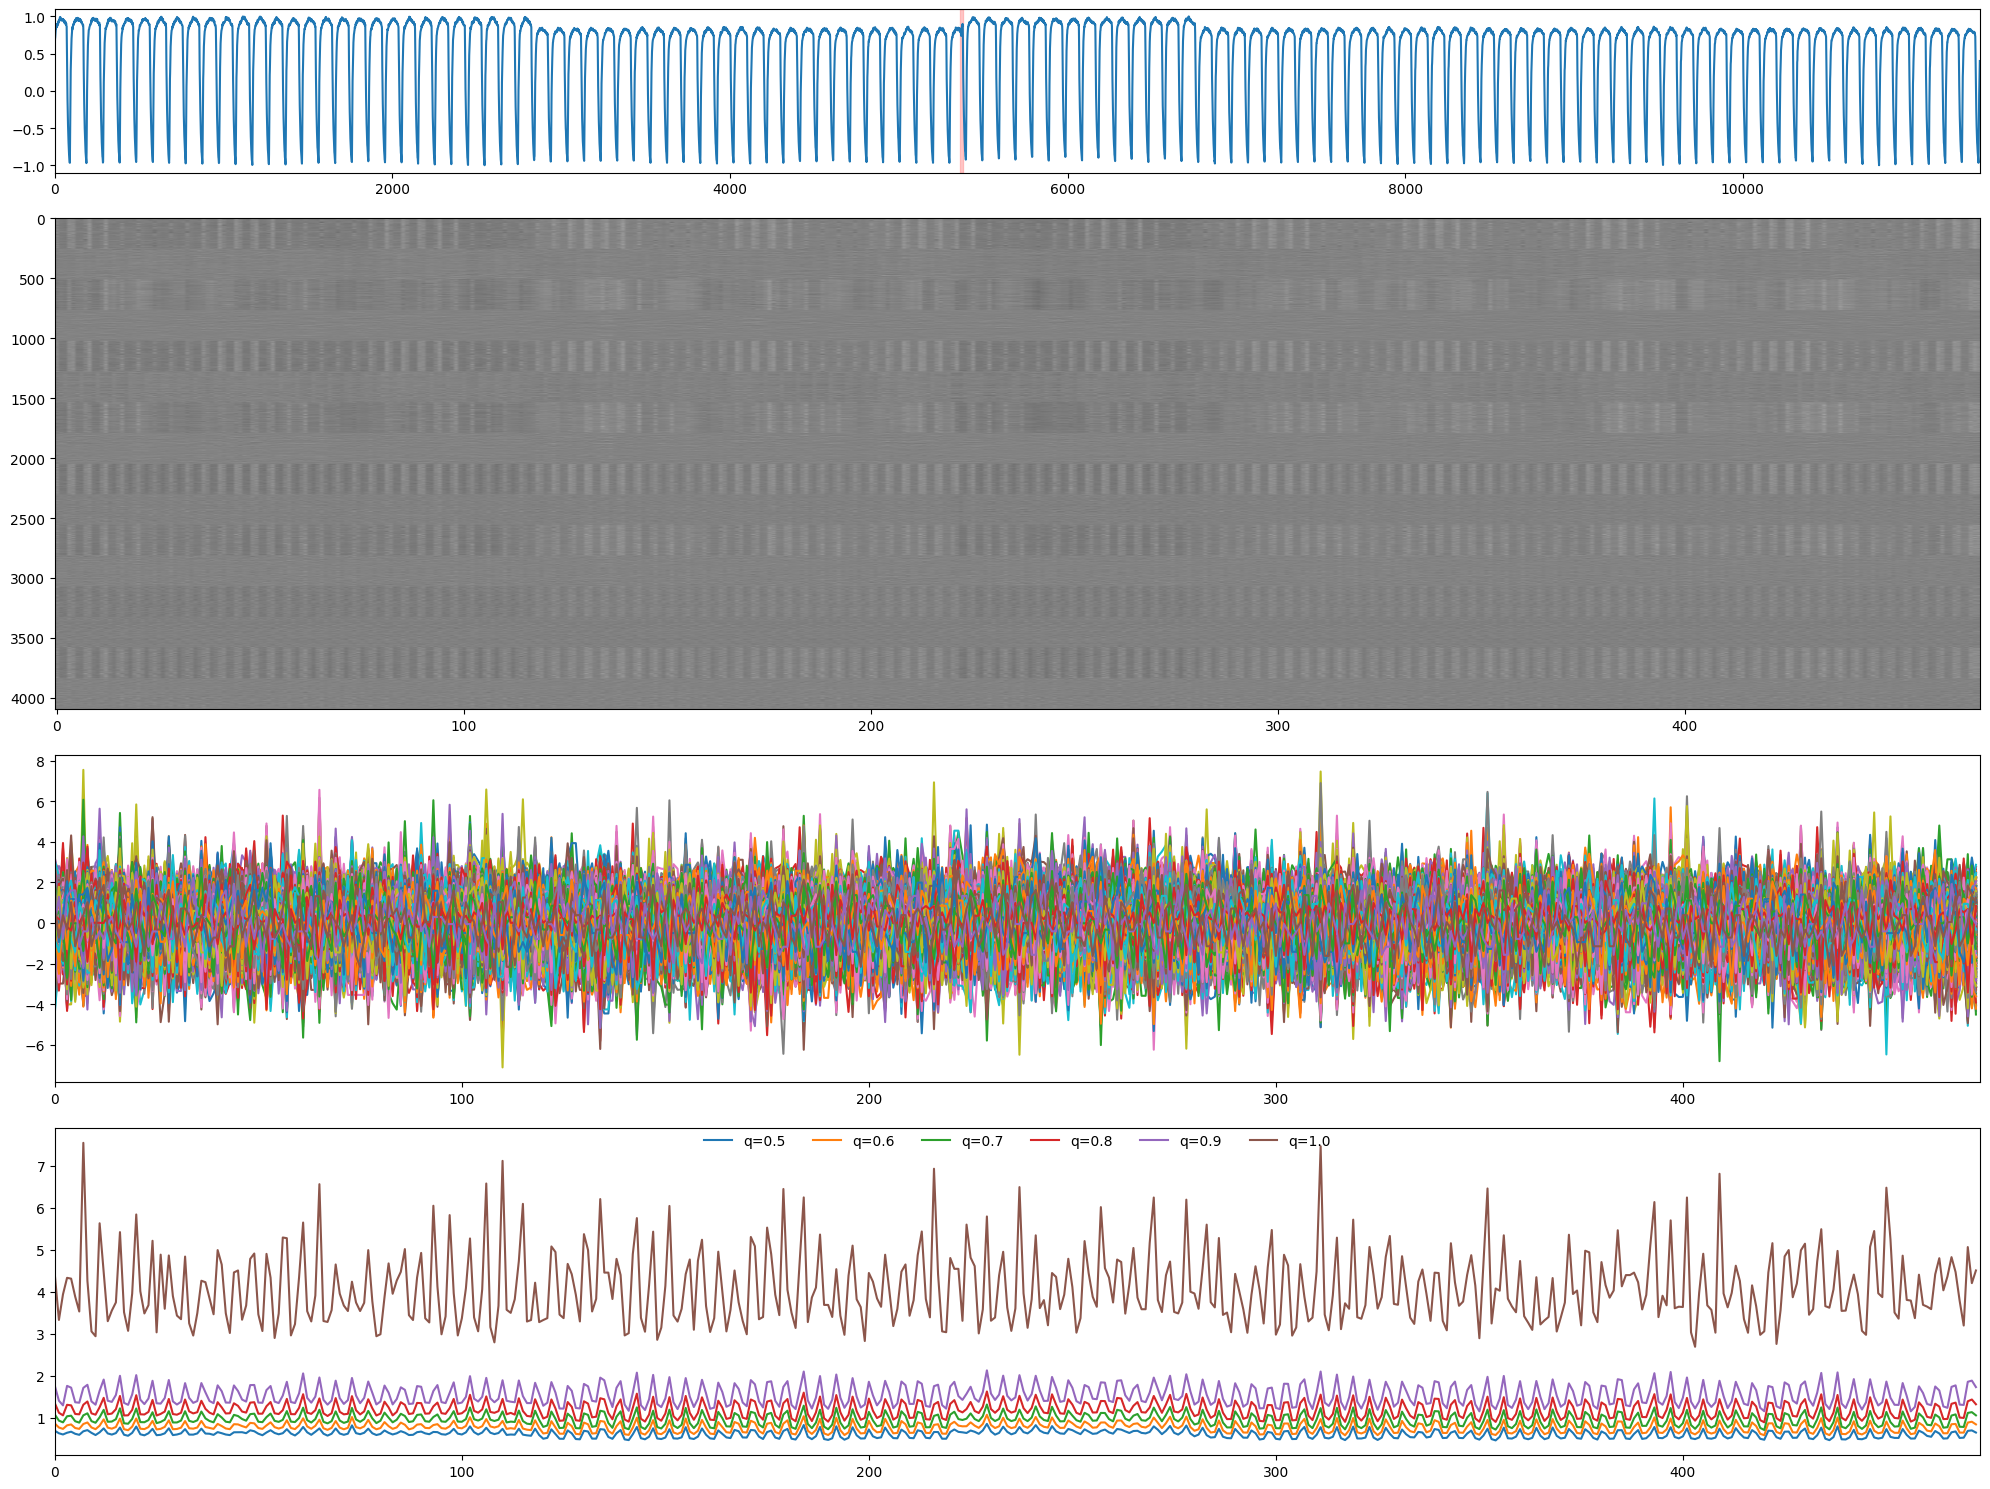

In [5]:
perform_analysis("../data/TSB-AD-U/347_UCR_id_45_Sensor_tr_2851_1st_5365.csv")

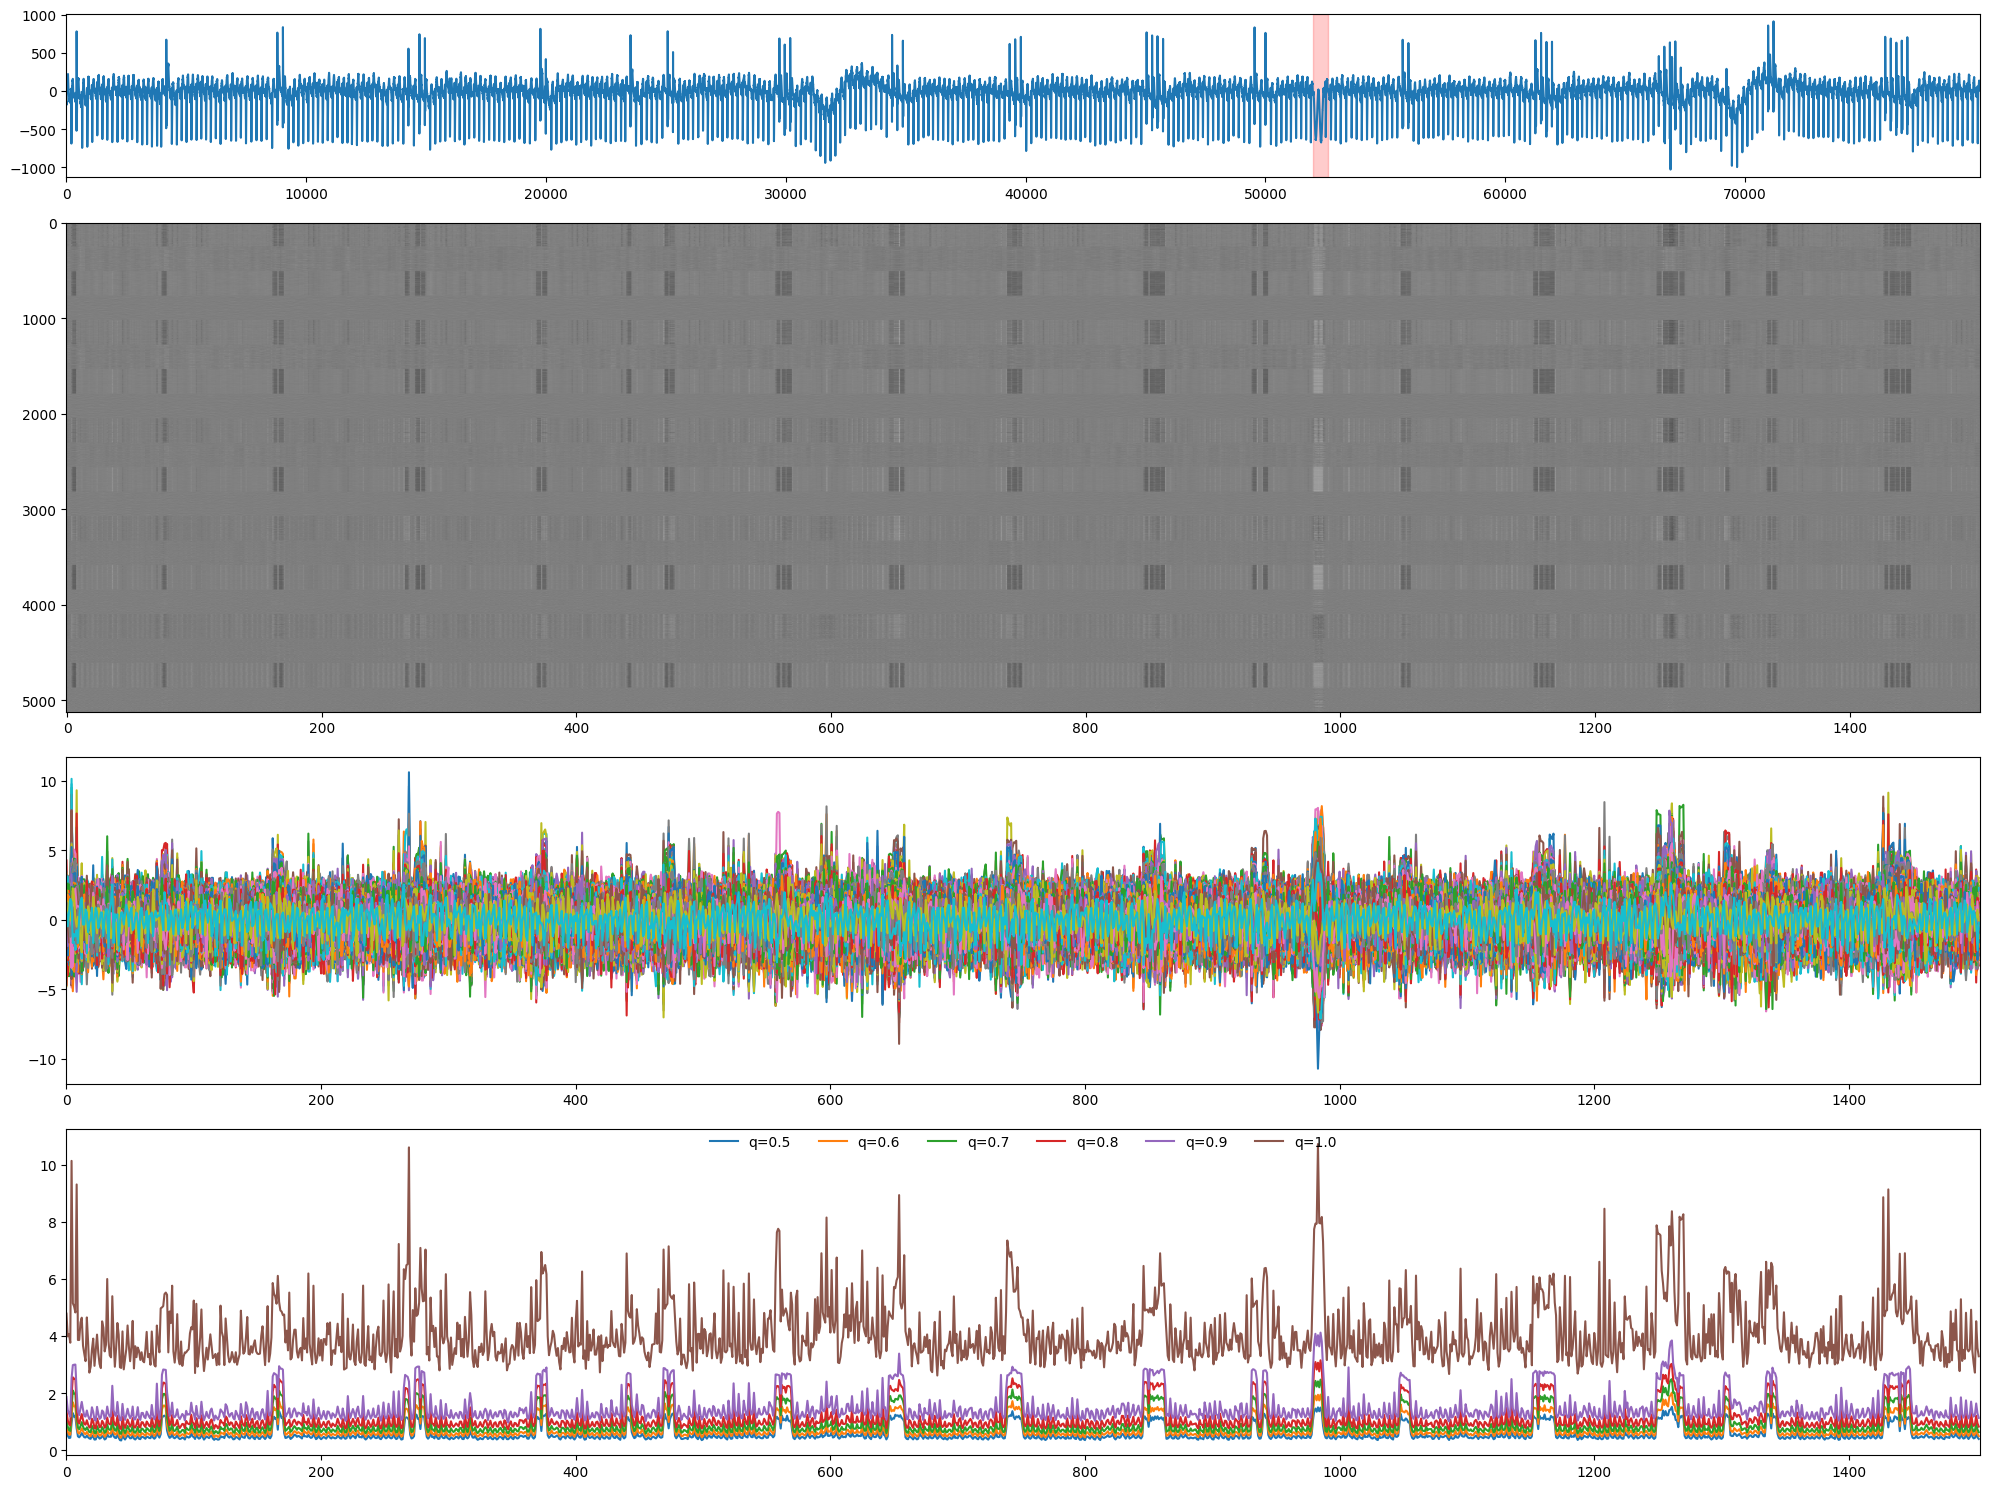

In [6]:
perform_analysis("../data/TSB-AD-U/312_UCR_id_10_Facility_tr_19948_1st_52000.csv")

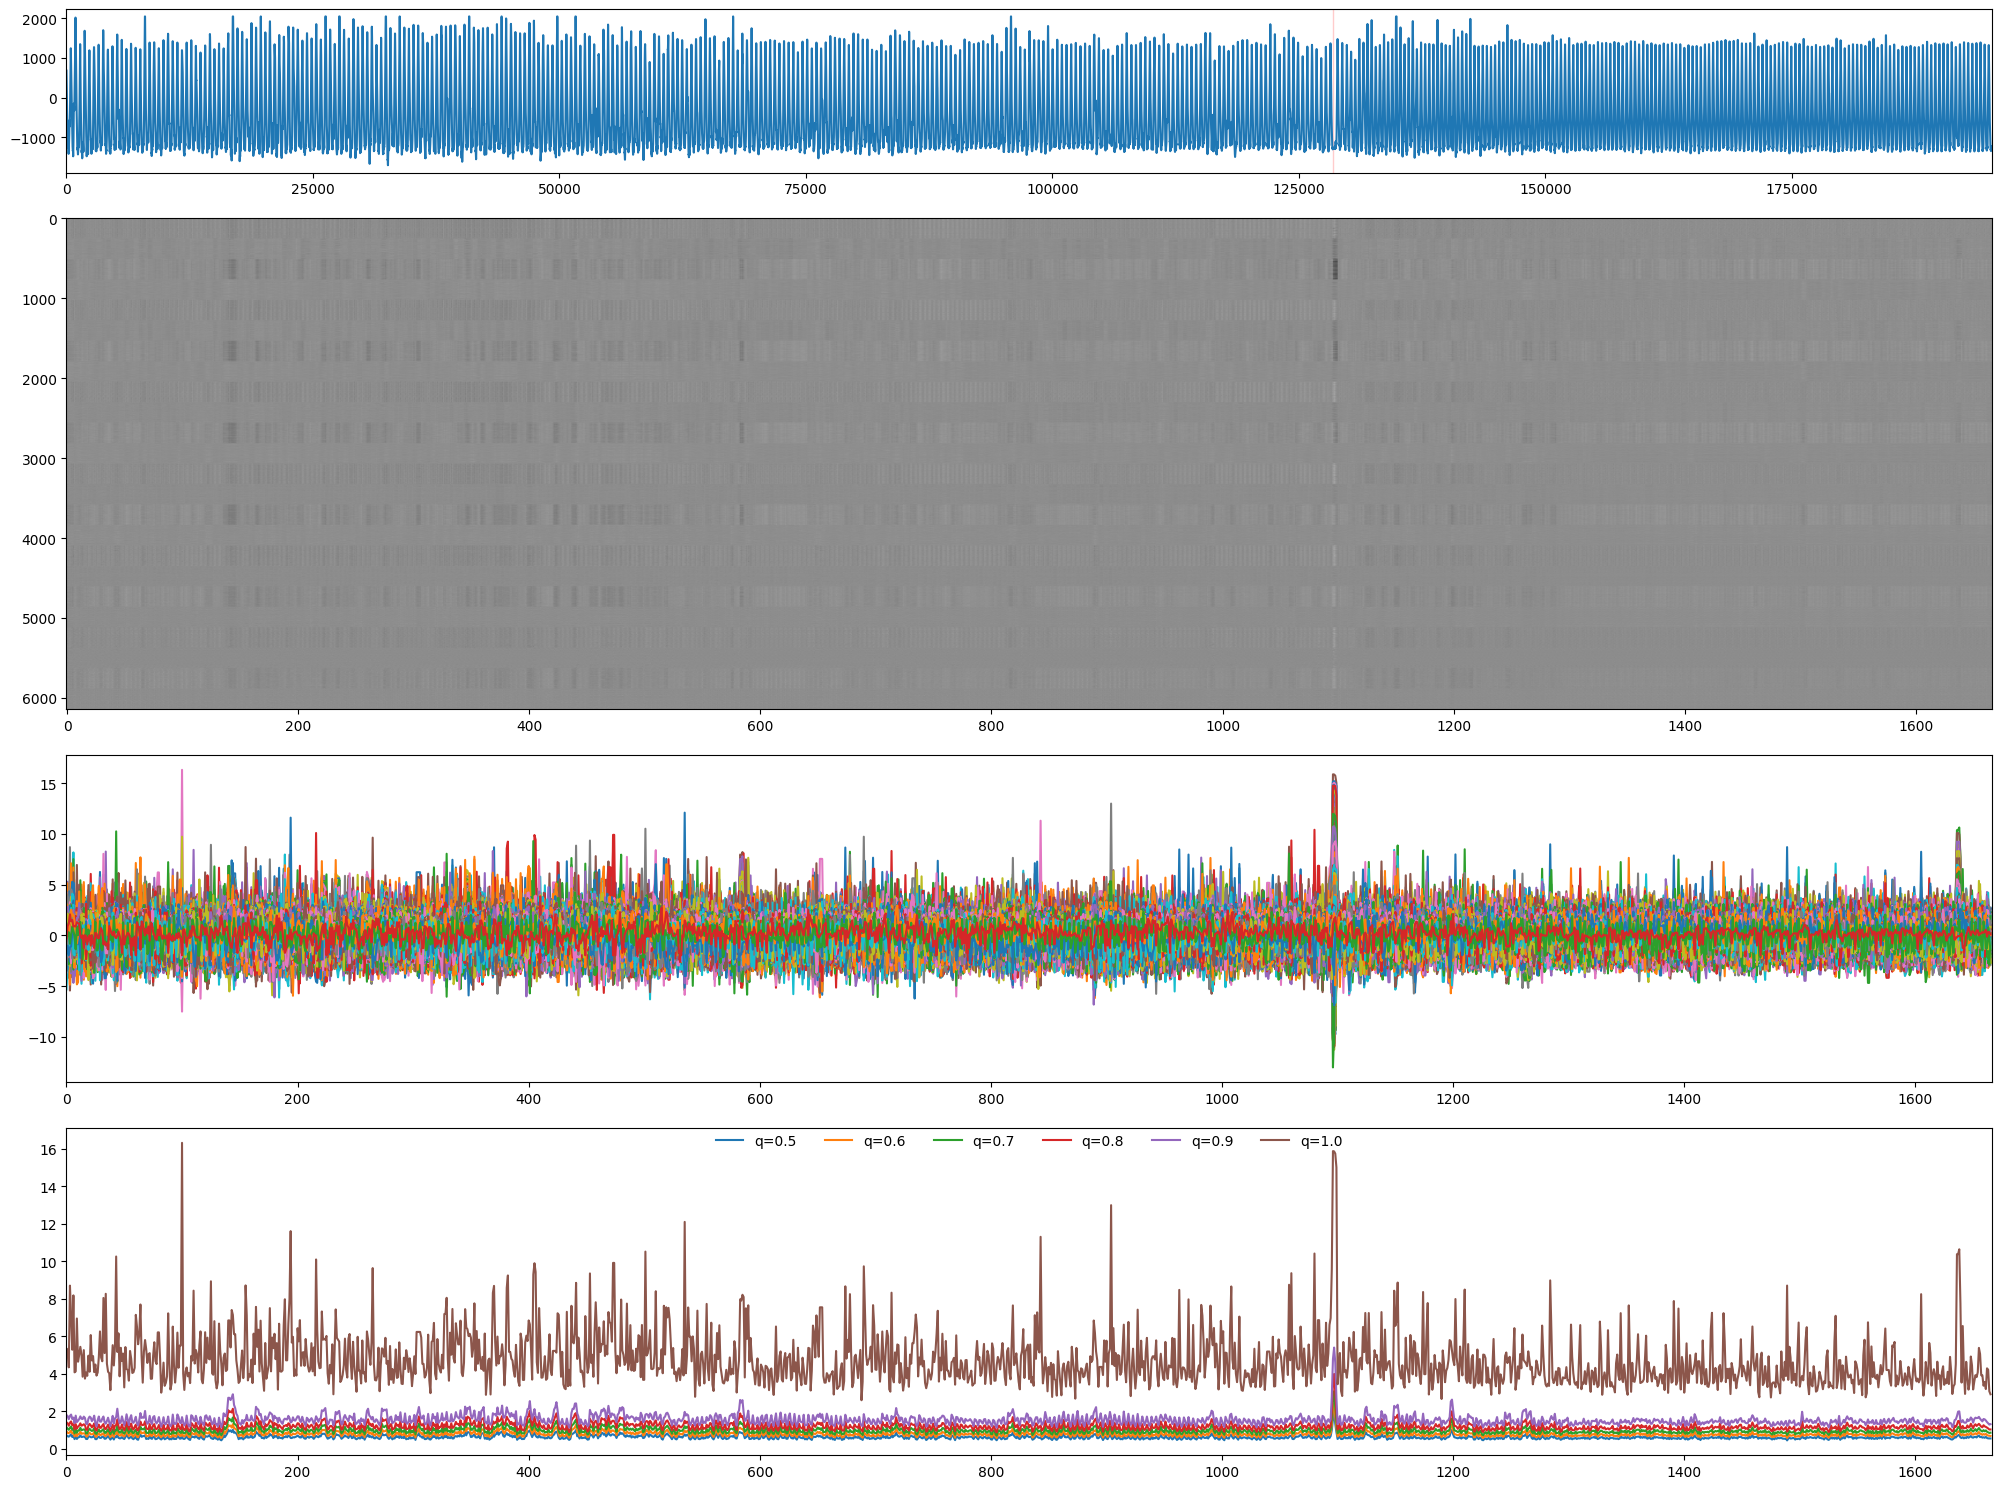

In [7]:
perform_analysis("../data/TSB-AD-U/323_UCR_id_21_HumanActivity_tr_48812_1st_128430.csv")